# Import Libraries

In [4]:
import numpy as np
import pandas as pd
from pathlib import Path
from matplotlib.pyplot import subplots, show
from statsmodels.api import OLS
from statsmodels.api import add_constant
import sklearn.model_selection as skm
import sklearn.linear_model as skl
from sklearn.preprocessing import StandardScaler
from ISLP import load_data
from ISLP.models import ModelSpec as MS
from functools import partial
from sklearn.pipeline import Pipeline # step-by-step recipe
from sklearn.decomposition import PCA # It reduces the number of features by combining them into new ones (called principal components) that keep the most important information.
from sklearn.cross_decomposition import PLSRegression #Partial Least Squares Regression, selects variables explain variance
from ISLP.models import \
     (Stepwise,
      sklearn_selected,
      sklearn_selection_path)
from l0bnb import fit_path # does subset selection (finds the path)
from statsmodels.api import Logit
from sklearn.tree import (DecisionTreeClassifier as DTC,
                          DecisionTreeRegressor as DTR,
                          plot_tree,
                          export_text)
from sklearn.ensemble import RandomForestRegressor as RF
from sklearn.ensemble import GradientBoostingRegressor as GBR

# Call Data and initialize variables

In [5]:
# exact data path
base_dir = Path(r"C:\Users\Admin\OneDrive - University of Toronto\School\Causal ML\code files")
data_path = base_dir / "dataverse_files" / "AER merged.dta"

# Dependent Variable
Y_cols = "amount"
# Independent Variables
X_cols = [
    "hpa","freq","mrm2","years","dormant","female","couple",
    "median_hhincome","psch_atlstba","powner","pop_propurban",
    "ave_hh_sz","page18_39"
]

df = pd.read_stata(data_path)
# turn Y string into list so we can add
regression_cols = [Y_cols, "gave", "treatment"] + X_cols
data = df[regression_cols]
# get rid of na's
data = data.dropna()
# separate outcome and predictors
Y=data[Y_cols]
# .copy() make separate copy of selected columns, leave data unchanged
X=data[["treatment"] + X_cols].copy()


# Interaction terms

In [6]:
# add interaction terms with treatment, make new column for each interaction
# inside X. LHS makes new column in X with name, RHS is interaction
for col in X_cols:
    X["treatment_x_" + col] = data["treatment"] * data[col]

# First Part Logit

In [7]:
# Specify first part outcome, donated or not
gave = data["gave"]

# Add intercept
X_logit = add_constant(X)

# Fit logit with robust standard errors
Model_logit = Logit(gave, X_logit).fit(cov_type="HC1")

# Results
print(Model_logit.summary())

# save each persons predicted probability of donating
p_donate = Model_logit.predict(X_logit)


Optimization terminated successfully.
         Current function value: 0.095030
         Iterations 9
                           Logit Regression Results                           
Dep. Variable:                   gave   No. Observations:                47114
Model:                          Logit   Df Residuals:                    47086
Method:                           MLE   Df Model:                           27
Date:                Sun, 04 Oct 2026   Pseudo R-squ.:                 0.06268
Time:                        17:39:32   Log-Likelihood:                -4477.2
converged:                       True   LL-Null:                       -4776.6
Covariance Type:                  HC1   LLR p-value:                5.246e-109
                                  coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
const                          -3.5490      0.744     -4.771      0.000   

# OLS Model

In [8]:
# add intercept
X = add_constant(X)

# People who donated only
positive = data["gave"] == 1

# Same donor rows for outcome and predictors
Y_positive = Y.loc[positive]
X_positive = X.loc[positive]

# run OLS controlling for possible heteroskedasticity in HPA
Model1 = OLS(Y_positive,X_positive).fit(cov_type="HC1")
# export as latex
# latex_output = Model1.summary().as_latex()
# with open("OLS_results.tex", "w") as f:
    # f.write(latex_output)

# look at model
print(Model1.summary())

# ridge makes its own intercept, axis=1 tells pandas to remove a column not row
# removing const column we made before from our X
D = X_positive.drop('const', axis=1)

                            OLS Regression Results                            
Dep. Variable:                 amount   R-squared:                       0.388
Model:                            OLS   Adj. R-squared:                  0.370
Method:                 Least Squares   F-statistic:                     9.288
Date:                Sun, 04 Oct 2026   Prob (F-statistic):           3.16e-33
Time:                        17:39:32   Log-Likelihood:                -4825.9
No. Observations:                 983   AIC:                             9708.
Df Residuals:                     955   BIC:                             9845.
Df Model:                          27                                         
Covariance Type:                  HC1                                         
                                  coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
const             

# Two part prediction

In [9]:
# Predicted gift amount conditional on donating for everyone
amount_pred_OLS = Model1.predict(X)

# Predicted dollars per person, including the possibility of no donation
two_part_pred_OLS = p_donate * amount_pred_OLS
print(two_part_pred_OLS.mean())

0.9276159952557674


# Set up ridge variables

In [10]:
# convert the pandas table into a NumPy array, a grid of numbers without column labels
X_ridge = np.asarray(D)

# standardize predictors, mean(0) calculates mean down the rows, giving one average per column
# [None,:] puts the averages into a single row array. None adds a dimension and : selects all the avgs
# Subtraction applies each column's average to every value in the column
Xs = X_ridge - X_ridge.mean(0)[None, :]

# calc each std per column
X_scale = X_ridge.std(0)

# divide each centered column by its own std
Xs = Xs / X_scale[None, :]

# linspace creates 100 evenly spaced numbers starting at 8 ending at -2
# 8 and 2 exps create a massive range of penalties
# divide by y std to adjust grids overall scale
# stores the 100 penalties under lambdas
lambdas = 10**np.linspace(8, -2, 100) / Y_positive.std()

# Ridge Coefficients

In [11]:
soln_array = skl.ElasticNet.path(Xs,# standardized predictors
                                 Y_positive, # donation amounts
                                 l1_ratio=0, # ridge penalty, lasso is 1
                                 alphas=lambdas, # use the penalties we made
                                 max_iter=100000, # more iterations to find coefs, 100k passes through the coefs
                                 tol=1e-8 # more accurate solution before stopping, check whether future updates are sufficiently small
                                 # and its solution is sufficiently accurate
                                 )[1] # selects second result

soln_path = pd.DataFrame(soln_array.T, # transpose array, pd.dataframe turns that array into a pandas
                         # table with labels
                         columns=D.columns, # D.columns supplies predictors names
                         index=-np.log(lambdas)) # sets the row labels to the negative nat log of each penalty
soln_path.index.name = 'negative log(lambda)'
# print(soln_path)

# Coefficient Plot

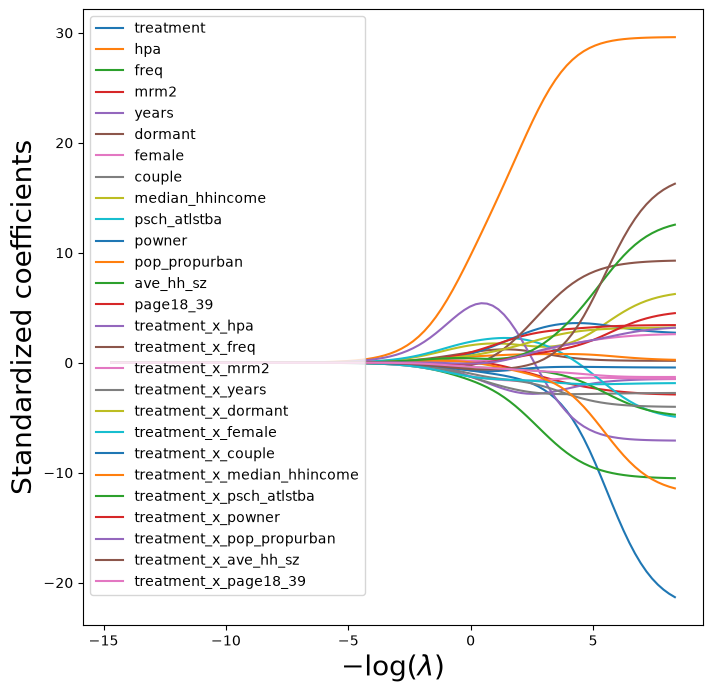

In [12]:
# create coef plot, subplots creates figure with a plotting area
# figsize 8 inches wide and tall
# path fig refers to whole figure, ax is plotting area where we draw lines and set labels
path_fig, ax = subplots(figsize=(8,8))
# .plot draws one line for each column, one per coef
# ax=ax tells pandas to draw on plotting area we just created
soln_path.plot(ax=ax, legend=False)

# set the axis labels and text size, $$ notation formats as math
# r keeps python from treating backslashes as escape chars
ax.set_xlabel(r'$-\log(\lambda)$', fontsize=20)
ax.set_ylabel('Standardized coefficients', fontsize=20)

# labels lines with predictor names and puts legend upper left
ax.legend(loc='upper left')

# save figure to same file to add to latex doc
path_fig.savefig(
    r"C:\Users\Admin\OneDrive - University of Toronto\School\Causal ML\code files\ridge_coefficients.pdf",
    bbox_inches="tight"
)

# Ridge CV

In [13]:
# ridge cross validation
K = 5

kfold = skm.KFold(n_splits=K, # request 5 folds
                  random_state=0, # make the split reproducible so rerunning gives same folds
                  shuffle=True # mixes observations before dividing so folds dont follow row order
                  )
ridge = skl.ElasticNet(l1_ratio=0, # ridge
                       max_iter=100000,
                       tol=1e-8)

# define standardization step
# subtract each columns mean, divide by its std, this is just the same as the manual one above
scaler = StandardScaler(with_mean=True, with_std=True)

pipe = Pipeline(steps=[  # steps of operation, scale/standardize and give name scalar
    ('scaler', scaler),
    ('ridge', ridge) # assign ridge model to 'ridge' after
])

# dictionary pairing param name with possible values, ridge is name of ridge step in pipeline
#__ connects step to one of its settings, alpha is penalty setting
# lambdas is 100 penalty values created
param_grid = {'ridge__alpha': lambdas} 
# gridsearch chooses the lambda param
grid = skm.GridSearchCV(pipe,  # standardize predictors then fit ridge
                        param_grid,  # repeat process for every penalty
                        cv=kfold, # use k fold
                        scoring='neg_mean_squared_error') # assess predictions using neg MSE

# performs the search: 100 penalties * 5 folds = 500 fits, auto refits selected model on supplied data
print("Starting cross-validation...", flush=True)
grid.fit(X_ridge,Y_positive)
print("cross-validation done", flush=True)
best_lambda = grid.best_params_['ridge__alpha'] # retrieve penalty with lowest average CV MSE

Starting cross-validation...
cross-validation done


# Combine Ridge amount predictions with logit probability

In [14]:
# Predict conditional gift amounts for everyone
amount_pred_ridge = grid.predict(X.drop("const", axis=1).to_numpy())

# Combine donation probability and conditional amount
two_part_pred_ridge = p_donate * amount_pred_ridge
print(two_part_pred_ridge.mean())

0.9276159952617677


# MSE Plot from CV

Selected lambda: 0.6482192078628978
lowest average CV MSE: 1343.0805388597041


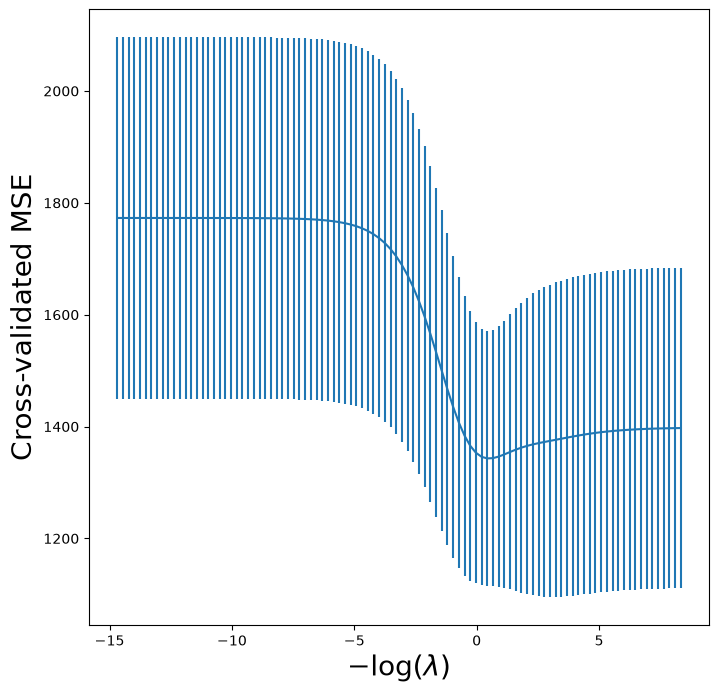

In [15]:
# set up figure
ridge_fig, ax = subplots(figsize=(8,8))
ax.errorbar(
    -np.log(lambdas), # neg natural log of each penalty
    -grid.cv_results_['mean_test_score'], # average validation MSE at each penalty
    yerr=grid.cv_results_['std_test_score']/np.sqrt(K) # how much validation varies over 5 folds, divide to get
    # approx SE. yett draws bars extending that amount above and below the avg
)

ax.set_xlabel(r'$-\log(\lambda)$', fontsize=20)
ax.set_ylabel('Cross-validated MSE', fontsize=20)
print("Selected lambda:", best_lambda)
print("lowest average CV MSE:", -grid.best_score_)

ridge_fig.savefig(
    r"C:\Users\Admin\OneDrive - University of Toronto\School\Causal ML\code files\ridge_MSECV.pdf",
    bbox_inches="tight"
)

# Lasso Model and plots

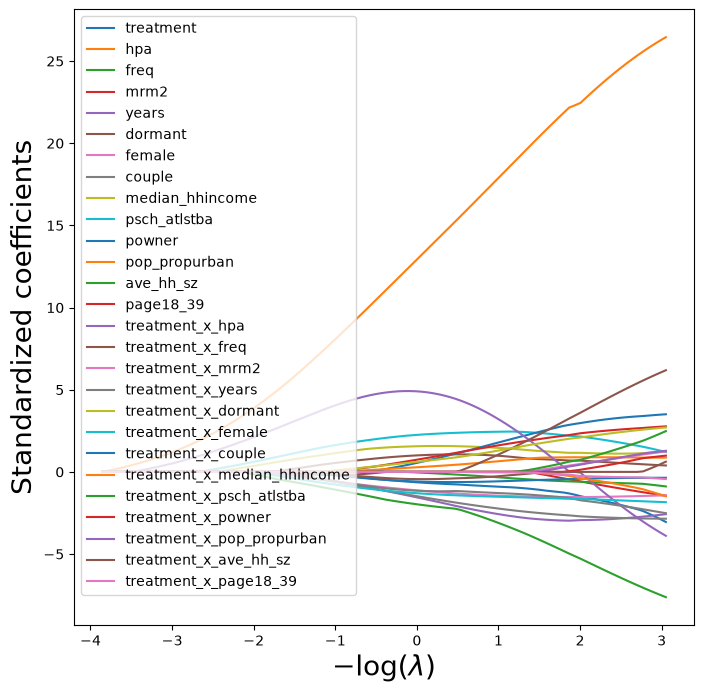

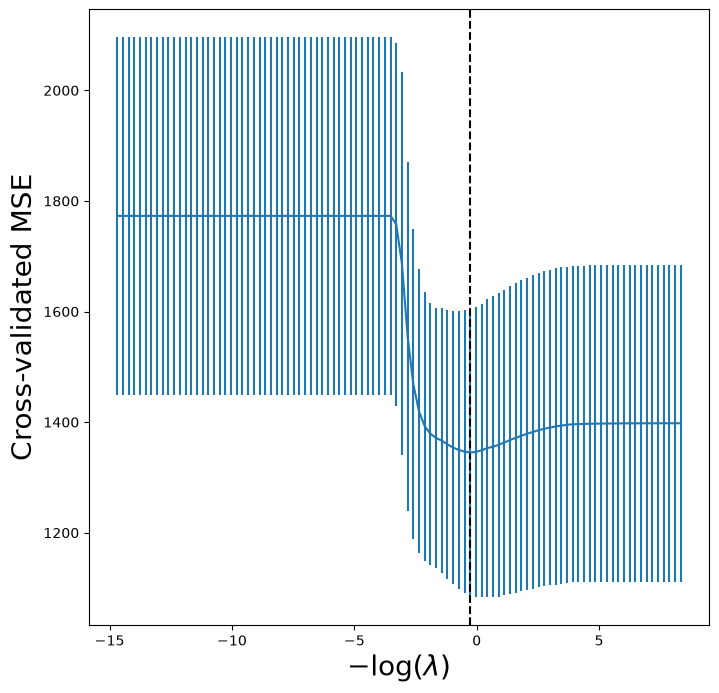

In [16]:
lassoCV = skl.ElasticNet(
    l1_ratio=1,       # Use the lasso penalty
    max_iter=100000,  # Maximum optimization iterations
    tol=1e-8         # Convergence tolerance
)

pipeCV = Pipeline(steps=[
    ('scalar', scaler),  # Standardize predictors
    ('lasso', lassoCV)   # Fit lasso
])

lasso_grid = skm.GridSearchCV(
    pipeCV,                           # Fit scaling and lasso inside each fold
    {'lasso__alpha': lambdas},         # Try your existing penalty grid
    cv=kfold,                         # Use your existing five folds
    scoring='neg_mean_squared_error'  # Choose the lowest average MSE
)

lasso_grid.fit(X_ridge, Y_positive)       # Fit using positive donors
pipeCV = lasso_grid.best_estimator_      # Retrieve the selected pipeline
tuned_lasso = pipeCV.named_steps['lasso'] # Retrieve its lasso model

lambdas, soln_array = skl.Lasso.path(
    Xs,           # Standardized positive-donor predictors
    Y_positive,   # Positive donation amounts
    alphas=100     # Calculate a coefficient path at 100 penalties
)[:2]             # Keep penalties and coefficients

soln_path = pd.DataFrame(
    soln_array.T,          # One row per penalty
    columns=D.columns,    # Predictor names
    index=-np.log(lambdas) # Negative log penalties for plotting
)

# plot coefs like ridge
path_fig, ax = subplots(figsize=(8,8))
soln_path.plot(ax=ax, legend=False)
ax.legend(loc='upper left')
ax.set_xlabel(r'$-\log(\lambda)$', fontsize=20)
ax.set_ylabel('Standardized coefficients', fontsize=20);

# plot CV error plot like ridge
lassoCV_fig, ax = subplots(figsize=(8, 8))

ax.errorbar(
    -np.log(lasso_grid.param_grid['lasso__alpha']),  # Penalties used in CV
    -lasso_grid.cv_results_['mean_test_score'],     # Average CV MSE
    yerr=lasso_grid.cv_results_['std_test_score'] / np.sqrt(K)  # Your existing bars
)

ax.axvline(
    -np.log(tuned_lasso.alpha),  # Selected penalty
    c='k',                      # Black line
    ls='--'                     # Dashed line
)
ax.set_xlabel(r'$-\log(\lambda)$', fontsize=20)
ax.set_ylabel('Cross-validated MSE', fontsize=20)

# Update path
path_fig.savefig(
    r"C:\Users\Admin\OneDrive - University of Toronto\School\Causal ML\code files\lasso_coefficients.pdf",
    bbox_inches="tight"
)
# Update path
lassoCV_fig.savefig(
    r"C:\Users\Admin\OneDrive - University of Toronto\School\Causal ML\code files\lasso_MSECV.pdf",
    bbox_inches="tight"
)

# Lasso amount predictions with logit probabiltiy

In [17]:
# Predict conditional gift amounts for everyone
amount_pred_lasso = pipeCV.predict(
    X.drop("const", axis=1).to_numpy()
)

# Combine donation probability and conditional amount
two_part_pred_lasso = p_donate * amount_pred_lasso
print(two_part_pred_lasso.mean())

0.9276159952617677


# Trees pt.1 Split into training and test then fit and plot

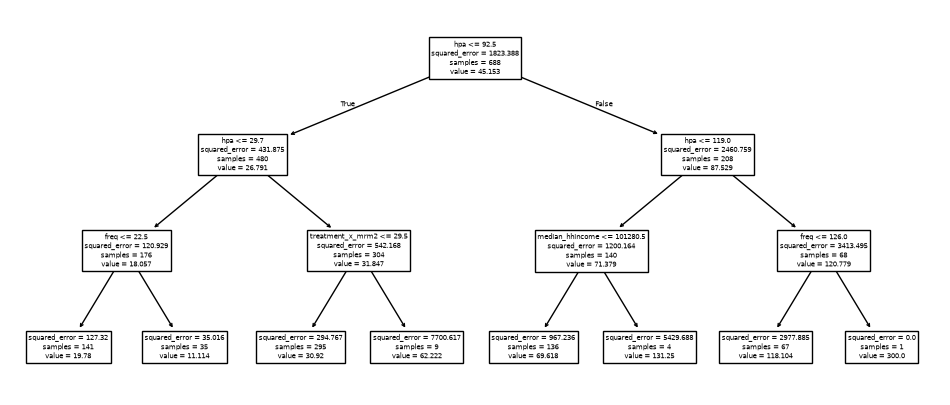

In [25]:
(X_train,
 X_test,
 y_train,
 y_test) = skm.train_test_split(
    D,              # Positive-donor predictors
    Y_positive,     # Positive donation amounts
    test_size=0.3,  # 30% test, 70% training
    random_state=0  # Reproducible split
)

reg = DTR(max_depth=3)
reg.fit(X_train, y_train) # learn splits using training donors only

ax = subplots(figsize=(12,5))[1] # get plotting area, [1] selects axes where tree is drawn
plot_tree(reg,
          feature_names=D.columns,  # predictor names
          ax=ax); # semi colon suppresses extra text output

# Save the figure containing the tree
ax.figure.savefig(base_dir / "regression_tree.pdf", bbox_inches="tight")

# Tree predicted gift amount multiplied by logit probabilities

In [19]:
# Predict conditional gift amounts for everyone
amount_pred_tree = reg.predict(X.drop("const", axis=1))

# Expected dollars = donation probability × conditional gift amount
two_part_pred_tree = p_donate * amount_pred_tree
print(two_part_pred_tree.mean())

0.8511674118092837


# Random Forest

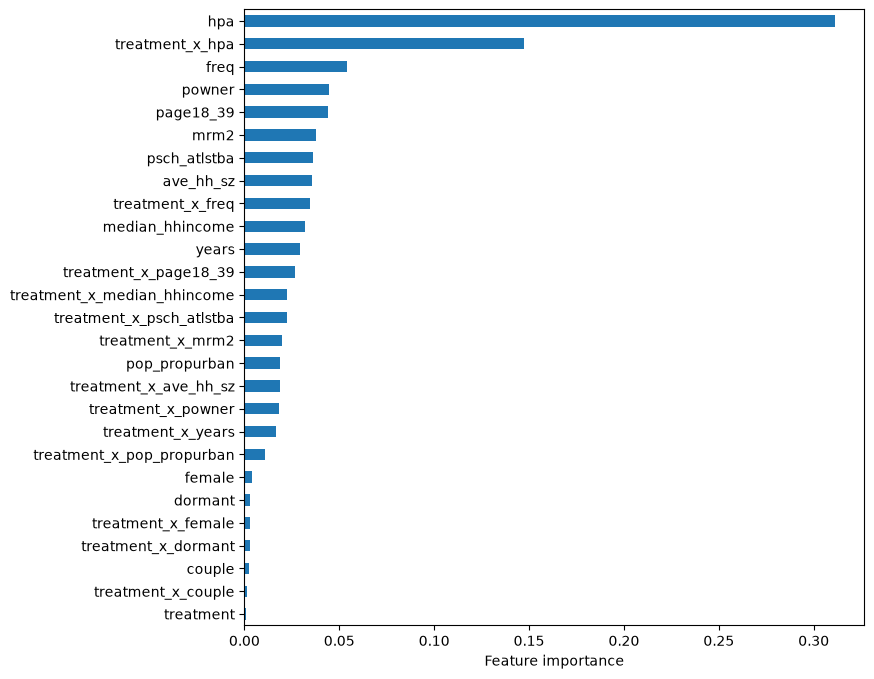

In [20]:
RF_donations = RF(
    max_features=6,  # Consider six predictors at each split
    random_state=0  # Make the result reproducible
).fit(X_train, y_train)  # Fit using training donors only
# Test MSE
y_hat_RF = RF_donations.predict(X_test)
np.mean((y_test - y_hat_RF)**2)

feature_imp = pd.DataFrame(
    {'importance': RF_donations.feature_importances_}, # Importance scores
    index=D.columns                                  # Predictor names
)

feature_imp.sort_values(
    by='importance', ascending=False  # Show most important features first
)

# Plot importance scores in ascending order
ax = feature_imp.sort_values('importance').plot.barh(
    legend=False, figsize=(8, 8)
)
ax.set_xlabel("Feature importance")

# Save the importance plot
ax.figure.savefig(base_dir / "RF_importance.pdf", bbox_inches="tight")

# Forest Two - Part prediction

In [21]:
# Predict gift size conditional on donating, for everyone
amount_pred_RF = RF_donations.predict(X.drop("const", axis=1))

# Expected dollars = donation probability × conditional gift size
two_part_pred_RF = p_donate * amount_pred_RF
print(two_part_pred_RF.mean())

0.8829572156656996


# Bagging

In [22]:
bag_donations = RF(max_features=X_train.shape[1], # Consider all predictors at each split
                   random_state=0)

bag_donations.fit(X_train, y_train) # Fit on training donors

y_hat_bag = bag_donations.predict(X_test) # Predict held-out gift amounts

mse_bag = np.mean((y_test - y_hat_bag)**2)  # Average squared prediction error

print("Bagging MSE:", mse_bag)  # Display test error

Bagging MSE: 698.028857187293


# Boosting

In [23]:
boost_donations = GBR(n_estimators=5000, # Build 5000 trees sequentially
                      learning_rate=0.001, # controls how much each new tree changes the current prediction
                      max_depth=3, # Limit each tree to 3 split levels
                      random_state=0) 
boost_donations.fit(X_train, y_train) # Fit on the same training donors

y_hate_boost = boost_donations.predict(X_test) # predict held-out gift amounts

y_hat_boost = boost_donations.predict(X_test)  # Predict test gift amounts

mse_boost = np.mean((y_test - y_hat_boost)**2)  # Average squared error

print("Boosting MSE:", mse_boost)  # Display test error


Boosting MSE: 601.1927021888996


# MSE/RMSE table

In [24]:
errors = pd.DataFrame({
    "Tree": np.mean((y_test - reg.predict(X_test))**2),
    "Random forest": np.mean((y_test - RF_donations.predict(X_test))**2),
    "Bagging": mse_bag,
    "Boosting": mse_boost
}, index=["MSE"]).T  # One row per model

errors["RMSE"] = np.sqrt(errors["MSE"])  # Error in donation dollars

# Export the table with three decimal places
errors.to_latex(base_dir / "tree_errors.tex", float_format="%.3f")

# DAG 1 - the experiment

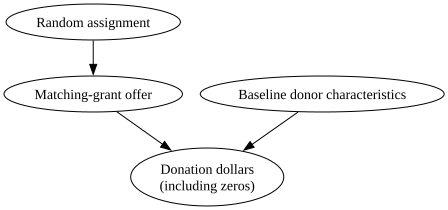

In [3]:
import graphviz

# Create directed graph in png format
experiment_dag = graphviz.Digraph(format='png') 

# Initialize nodes
experiment_dag.node('R', label='Random assignment')
experiment_dag.node('D', label='Matching-grant offer')
experiment_dag.node('Y', label='Donation dollars\n(including zeros)')
experiment_dag.node('X', label='Baseline donor characteristics')

# Make edges
experiment_dag.edges(['RD', 'DY', 'XY'])

experiment_dag

# DAG 2 The biased sample

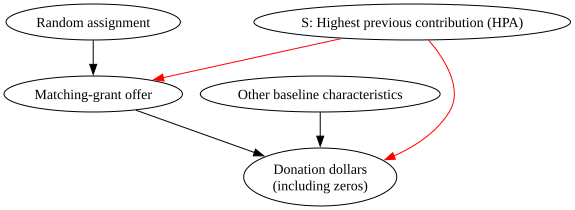

In [4]:
# Create empty directional graph
biased_dag = graphviz.Digraph(format='png')

# Create nodes
biased_dag.node('R', label='Random assignment')
biased_dag.node('D', label='Matching-grant offer')
biased_dag.node('Y', label='Donation dollars\n(including zeros)')
biased_dag.node('X', label='Other baseline characteristics')
biased_dag.node('S', label='S: Highest previous contribution (HPA)')

# Set the edges
biased_dag.edges(['RD', 'DY', 'XY'])

biased_dag.edge('S', 'D', color='red')
biased_dag.edge('S', 'Y', color='red')

biased_dag